<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/aidl_lab16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cuda

Dataset Loaded Successfully
Training samples: 120000
Testing samples: 7600
   label                                              title  \
0      2  Wall St. Bears Claw Back Into the Black (Reuters)   
1      2  Carlyle Looks Toward Commercial Aerospace (Reu...   
2      2    Oil and Economy Cloud Stocks' Outlook (Reuters)   
3      2  Iraq Halts Oil Exports from Main Southern Pipe...   
4      2  Oil prices soar to all-time record, posing new...   

                                         description  \
0  Reuters - Short-sellers, Wall Street's dwindli...   
1  Reuters - Private investment firm Carlyle Grou...   
2  Reuters - Soaring crude prices plus worries\ab...   
3  Reuters - Authorities have halted oil export\f...   
4  AFP - Tearaway world oil prices, toppling reco...   

                                                text  
0  Wall St. Bears Claw Back Into the Black (Reute...  
1  Carlyle Looks Toward Commercial Aerospace (Reu...  
2  Oil and Economy Cloud

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(



Epoch 1/5
Training Loss: 0.7911
Training Accuracy: 0.6857
Validation Loss: 0.5399
Validation Accuracy: 0.8047

Epoch 2/5
Training Loss: 0.4715
Training Accuracy: 0.8295
Validation Loss: 0.4241
Validation Accuracy: 0.8512

Epoch 3/5
Training Loss: 0.377
Training Accuracy: 0.867
Validation Loss: 0.387
Validation Accuracy: 0.8678

Epoch 4/5
Training Loss: 0.3256
Training Accuracy: 0.8864
Validation Loss: 0.3547
Validation Accuracy: 0.8804

Epoch 5/5
Training Loss: 0.2875
Training Accuracy: 0.9003
Validation Loss: 0.3423
Validation Accuracy: 0.8833


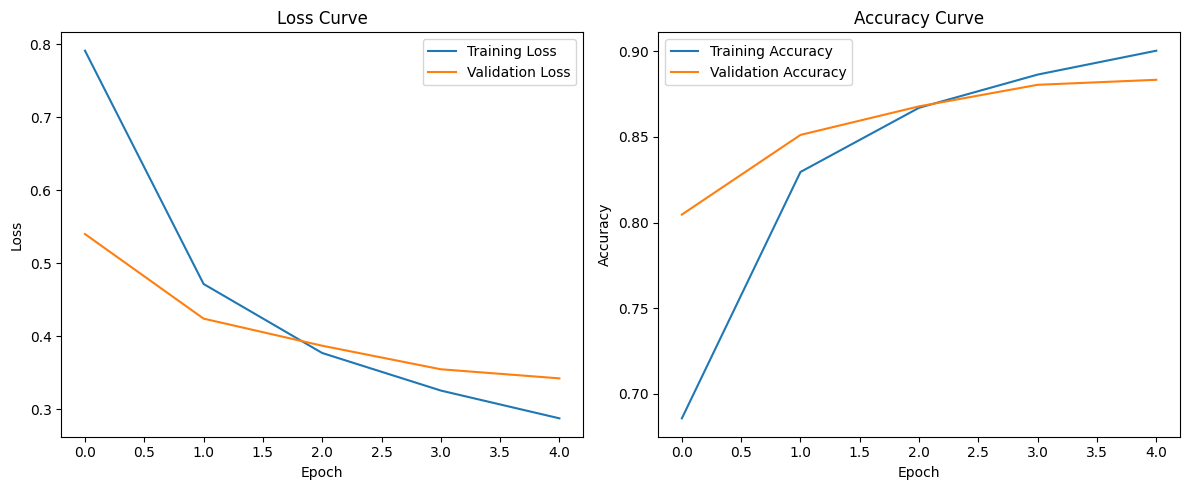


TRANSFORMER EVALUATION
Accuracy: 0.8798684210526316
Precision: 0.8814210666139979
Recall: 0.8798684210526316
F1 Score: 0.8797979535495882

Classification Report:
              precision    recall  f1-score   support

       World       0.91      0.85      0.88      1900
      Sports       0.92      0.96      0.94      1900
    Business       0.81      0.88      0.84      1900
    Sci/Tech       0.88      0.83      0.85      1900

    accuracy                           0.88      7600
   macro avg       0.88      0.88      0.88      7600
weighted avg       0.88      0.88      0.88      7600



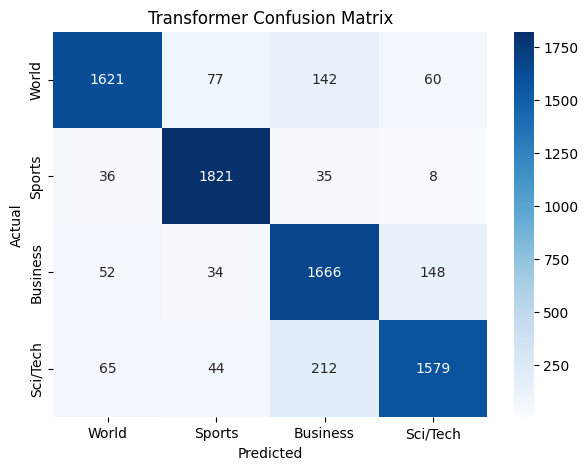


BASELINE MODEL RESULTS
Accuracy: 0.9221052631578948
Precision: 0.9219127226681603
Recall: 0.9221052631578948
F1 Score: 0.9219423661614152

MODEL COMPARISON
                          Model  Accuracy  Precision  Recall  F1 Score
0  TF-IDF + Logistic Regression    0.9221     0.9219  0.9221    0.9219
1           Transformer Encoder    0.8799     0.8814  0.8799    0.8798


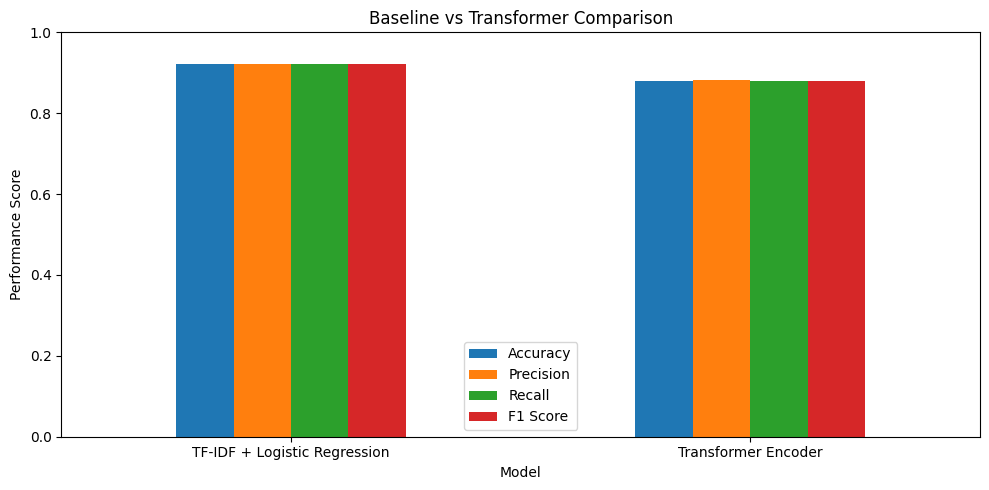


SAMPLE PREDICTIONS

Actual: Business
Predicted: Business
Correct: True

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: Sports
Correct: False

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: Sci/Tech
Correct: True

Actual: Sci/Tech
Predicted: World
Correct: False

Actual: Sci/Tech
Predicted: Business
Correct: False

EXPERIMENT COMPLETED SUCCESSFULLY
Dataset: AG News
Architecture: Transformer Encoder
Number of Classes: 4
Transformer Test Accuracy: 0.8799
Baseline Test Accuracy: 0.9221

Conclusion:
Transformer Encoder was implemented and evaluated for AG News text classification. Its performance was compared with TF-IDF Logistic Regression.


In [ ]:

# ============================================================
# LAB / EXP 16: TRANSFORMER ENCODER BLOCK
# Dataset: AG News Classification
# ============================================================

# 1. IMPORT LIBRARIES

import os
import re
import urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# 2. DOWNLOAD AG NEWS DATASET

os.makedirs("ag_news", exist_ok=True)

base_url = (
    "https://raw.githubusercontent.com/"
    "mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"
)

for split in ["train", "test"]:

    path = f"ag_news/{split}.csv"

    if not os.path.exists(path):

        urllib.request.urlretrieve(
            base_url + split + ".csv",
            path
        )

columns = ["label", "title", "description"]

train_df = pd.read_csv(
    "ag_news/train.csv",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    "ag_news/test.csv",
    header=None,
    names=columns
)

# Combine title and description

train_df["text"] = (
    train_df["title"].fillna("") + " " +
    train_df["description"].fillna("")
)

test_df["text"] = (
    test_df["title"].fillna("") + " " +
    test_df["description"].fillna("")
)

# Convert labels from 1-4 to 0-3

train_df["label"] = train_df["label"] - 1
test_df["label"] = test_df["label"] - 1

print("\nDataset Loaded Successfully")

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print(train_df.head())


# 3. DATA PREPROCESSING

def tokenize(text):

    return re.findall(
        r"[A-Za-z0-9]+",
        str(text).lower()
    )


train_data, val_data = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

MAX_VOCAB = 30000
MAX_LEN = 128

counter = Counter()

for text in train_data["text"]:

    counter.update(tokenize(text))


vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(MAX_VOCAB - 2):

    vocab[word] = len(vocab)


print("\nVocabulary Size:", len(vocab))


def encode(text):

    tokens = tokenize(text)

    ids = [
        vocab.get(word, vocab["<UNK>"])
        for word in tokens[:MAX_LEN]
    ]

    ids = ids + [0] * (MAX_LEN - len(ids))

    return ids


# 4. CREATE PYTORCH DATASET

class NewsDataset(Dataset):

    def __init__(self, dataframe):

        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["label"].tolist()

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        text = encode(self.texts[index])

        label = self.labels[index]

        return (
            torch.tensor(text, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )


BATCH_SIZE = 128

train_dataset = NewsDataset(train_data)
val_dataset = NewsDataset(val_data)
test_dataset = NewsDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)


# 5. TRANSFORMER ENCODER ARCHITECTURE

class TransformerClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        num_heads=4,
        num_layers=2,
        num_classes=4
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        self.position_embedding = nn.Embedding(
            MAX_LEN,
            embed_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.dropout = nn.Dropout(0.2)

        self.fc = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        padding_mask = (x == 0)

        positions = torch.arange(
            x.size(1),
            device=x.device
        ).unsqueeze(0)

        x = (
            self.embedding(x) +
            self.position_embedding(positions)
        )

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        mask = (~padding_mask).unsqueeze(-1).float()

        x = (x * mask).sum(dim=1)

        x = x / mask.sum(dim=1).clamp(min=1)

        x = self.dropout(x)

        output = self.fc(x)

        return output


model = TransformerClassifier(
    vocab_size=len(vocab)
).to(device)

print("\nTransformer Model:")
print(model)


# 6. TRAINING THE MODEL

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0002,
    weight_decay=0.0001
)

EPOCHS = 5

train_losses = []
val_losses = []

train_accs = []
val_accs = []


def evaluate(model, loader):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return total_loss / total, correct / total


for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    val_loss, val_acc = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    print("Training Loss:", round(train_loss, 4))
    print("Training Accuracy:", round(train_acc, 4))

    print("Validation Loss:", round(val_loss, 4))
    print("Validation Accuracy:", round(val_acc, 4))


torch.save(
    model.state_dict(),
    "transformer_model.pth"
)


# 7. VISUALIZE LOSS AND ACCURACY

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(train_accs, label="Training Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


# 8. TEST MODEL EVALUATION

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)


print("\nTRANSFORMER EVALUATION")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


class_names = [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
]

print("\nClassification Report:")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))


# 9. CONFUSION MATRIX

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Transformer Confusion Matrix")

plt.show()


# 10. BASELINE MODEL: TF-IDF + LOGISTIC REGRESSION

tfidf = TfidfVectorizer(
    max_features=200000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train = tfidf.fit_transform(
    train_data["text"]
)

X_test = tfidf.transform(
    test_df["text"]
)

baseline_model = LogisticRegression(
    max_iter=1000,
    C=4.0
)

baseline_model.fit(
    X_train,
    train_data["label"]
)

baseline_predictions = baseline_model.predict(X_test)


baseline_accuracy = accuracy_score(
    test_df["label"],
    baseline_predictions
)

baseline_precision = precision_score(
    test_df["label"],
    baseline_predictions,
    average="weighted"
)

baseline_recall = recall_score(
    test_df["label"],
    baseline_predictions,
    average="weighted"
)

baseline_f1 = f1_score(
    test_df["label"],
    baseline_predictions,
    average="weighted"
)


print("\nBASELINE MODEL RESULTS")

print("Accuracy:", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1 Score:", baseline_f1)


# 11. COMPARE BOTH MODELS

results = pd.DataFrame({

    "Model": [
        "TF-IDF + Logistic Regression",
        "Transformer Encoder"
    ],

    "Accuracy": [
        baseline_accuracy,
        accuracy
    ],

    "Precision": [
        baseline_precision,
        precision
    ],

    "Recall": [
        baseline_recall,
        recall
    ],

    "F1 Score": [
        baseline_f1,
        f1
    ]

})

print("\nMODEL COMPARISON")

print(results.round(4))


results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Baseline vs Transformer Comparison")

plt.ylabel("Performance Score")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()


# 12. SAMPLE PREDICTIONS

print("\nSAMPLE PREDICTIONS")

for i in range(10):

    actual = class_names[all_labels[i]]

    predicted = class_names[all_predictions[i]]

    print("\nActual:", actual)

    print("Predicted:", predicted)

    print(
        "Correct:",
        actual == predicted
    )


# 13. FINAL RESULT

print("\n================================")
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("================================")

print("Dataset: AG News")

print("Architecture: Transformer Encoder")

print("Number of Classes: 4")

print("Transformer Test Accuracy:", round(accuracy, 4))

print("Baseline Test Accuracy:", round(baseline_accuracy, 4))

print("\nConclusion:")
print(
    "Transformer Encoder was implemented and evaluated "
    "for AG News text classification. Its performance "
    "was compared with TF-IDF Logistic Regression."
)
